# Dynamic hierarchical points model: evaluation and live-state monitoring

The model separates immediately observable role and context from a slowly changing player state:

\[
a_{i,t}=a_{i,t-1}+\epsilon_{i,t}, \qquad
y_{i,t}=x_{i,t}^{\mathsf T}\beta+\alpha_{\mathrm{position}}+\alpha_{\mathrm{team}}+a_{i,t}+\eta_{i,t}.
\]

Minutes, shot volume, rest, opponent defense, home court, position, and team determine the shared pregame component. A Kalman update moves the latent state only after a completed game's points are observed. The configured 0.35-point game drift and 2.0-point offseason drift are explicit assumptions, not values selected on an evaluation season.

**Status and leakage contract.** Each walk-forward fold fits on the two complete seasons immediately preceding its evaluation season. Lagged role features, opponent defense, and player state use only information available before each game; the current game's points enter only the postgame state update. Fold audits and causal assertions below make that contract visible.

**Two distinct outputs.** The multi-season walk-forward trace is an out-of-sample evaluation. The final section rebuilds the latest-season state causally from the latest two complete prior seasons and shows each player's most recently updated state. It is monitoring of observed live state, **not a future-game forecast**: no future schedule, opponent, or role row is supplied.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("run this notebook from inside the nba_quant repository")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models.dynamic_points import (
    DynamicPointsConfig,
    build_causal_frame,
    walk_forward_trace,
)
from src.models.dynamic_points_diagnostics import (
    core_calibration,
    gain_summary,
    group_calibration,
    offseason_summary,
    posterior_draw_summary,
    shrinkage_summary,
    variance_decomposition,
)

sns.set_theme(style="whitegrid")
CONFIG = DynamicPointsConfig(
    state_drift_sd=0.35,
    offseason_drift_sd=2.0,
    train_window_seasons=2,
    min_group_n=30,
)
SEASON_PATHS = sorted(
    ROOT.glob("data/silver/nba/*/regular_season/player_gamelogs.parquet")
)
if len(SEASON_PATHS) < CONFIG.train_window_seasons + 1:
    raise ValueError("need at least three complete season parquet files")

print(f"Repository root: {ROOT}")
print(f"Discovered {len(SEASON_PATHS)} season files")

Repository root: /Users/alexgonzalez/Documents/nba_quant
Discovered 8 season files


In [2]:
season_frames = []
raw_rows = 0
for season_path in SEASON_PATHS:
    season = pd.read_parquet(season_path)
    raw_rows += len(season)
    season = season.loc[season["season_type"].eq("Regular Season")].copy()
    season_frames.append(season)

games = pd.concat(season_frames, ignore_index=True)
missing_position_rows = int(games["pos"].isna().sum())
games["pos"] = games["pos"].fillna("UNK").astype(str)
print(
    f"Loaded {raw_rows:,} rows; retained {len(games):,} regular-season rows "
    f"from {len(SEASON_PATHS)} files."
)
print(
    f"Normalized {missing_position_rows:,} missing position values to the "
    "explicit 'UNK' category; no rows were dropped."
)

causal, causal_audit = build_causal_frame(games)
print("Causal-frame audit:")
display(pd.DataFrame([causal_audit]))

available_seasons = sorted(
    causal["season_year"].astype(str).unique(),
    key=lambda value: int(value.split("-")[0]),
)
evaluation_seasons = tuple(available_seasons[CONFIG.train_window_seasons :])
trace, fold_audits = walk_forward_trace(
    causal,
    evaluation_seasons=evaluation_seasons,
    config=CONFIG,
)
fold_audit_table = pd.DataFrame(fold_audits)
print("Walk-forward fold audits (every evaluation fold):")
display(fold_audit_table)

if trace.empty:
    raise AssertionError("walk-forward evaluation trace must not be empty")
numeric_trace = trace.select_dtypes(include="number")
if numeric_trace.empty or not np.isfinite(numeric_trace.to_numpy(dtype=float)).all():
    raise AssertionError("numeric diagnostic columns must be finite")
trace_key = ["season_year", "player_id", "game_id"]
if trace.duplicated(trace_key).any():
    raise AssertionError("trace must contain one row per player/game/fold")
if set(trace["season_year"].unique()) != set(evaluation_seasons):
    raise AssertionError("every requested evaluation season must appear in the trace")
print(
    f"Validated {len(trace):,} causal predictions across "
    f"{len(evaluation_seasons)} evaluation seasons: {', '.join(evaluation_seasons)}"
)

Loaded 178,335 rows; retained 178,335 regular-season rows from 8 files.
Normalized 224 missing position values to the explicit 'UNK' category; no rows were dropped.
Causal-frame audit:


,input_rows,non_regular_season_rows_removed,nonpositive_minute_rows_removed,missing_minute_rows_removed,output_rows,minutes_missing_values,fga_missing_values,fta_missing_values,team_def_rating_missing_values
0,178335,0,13,0,178322,0,0,0,0


Walk-forward fold audits (every evaluation fold):


,train_seasons,evaluation_season,candidate_rows,fitted_rows,zero_minute_rows_removed,imputed_feature_cells,predicted_rows,evaluation_imputed_feature_cells,evaluation_rows_with_imputation
0,"(2019-20, 2020-21)",2021-22,45446,45446,0,3955,26036,1028,605
1,"(2020-21, 2021-22)",2022-23,49090,49090,0,1883,25892,800,539
2,"(2021-22, 2022-23)",2023-24,51928,51928,0,1828,26399,875,572
3,"(2022-23, 2023-24)",2024-25,52291,52291,0,1675,26303,884,569
4,"(2023-24, 2024-25)",2025-26,52702,52702,0,1759,26649,894,582
5,"(2024-25, 2025-26)",2026-27,52952,52952,0,1778,1597,580,430


Validated 132,876 causal predictions across 6 evaluation seasons: 2021-22, 2022-23, 2023-24, 2024-25, 2025-26, 2026-27


Core calibration:


,n,seasons,mean_z,sd_z,rmse,mae,coverage_50,coverage_80,coverage_90,coverage_95
0,132876,"(2021-22, 2022-23, 2023-24, 2024-25, 2025-26, ...",-0.006967,0.965815,6.057041,4.633507,0.561712,0.837036,0.914928,0.95176


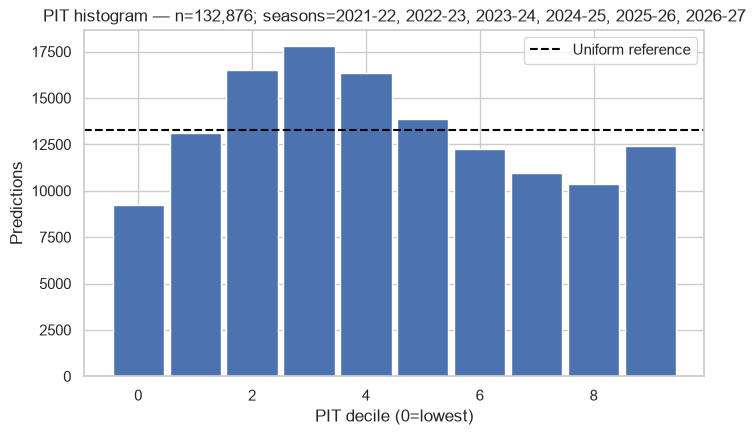

Variance decomposition and coverage by games-in-model tier:


,games_tier,n,state_plugin_scale_squared_share,observation_plugin_scale_squared_share,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95
0,60+,108196,0.066587,0.933413,0.004861,0.994410,0.545113,0.824984,0.906873,0.946819
1,30-59,11468,0.070388,0.929612,0.027218,0.846295,0.630799,0.886467,0.941838,0.967475
2,10-29,8097,0.069998,0.930002,-0.029450,0.804835,0.658515,0.901074,0.952081,0.975299
3,0-9,5115,0.081415,0.918585,-0.298218,0.770157,0.604692,0.879765,0.966178,0.983773


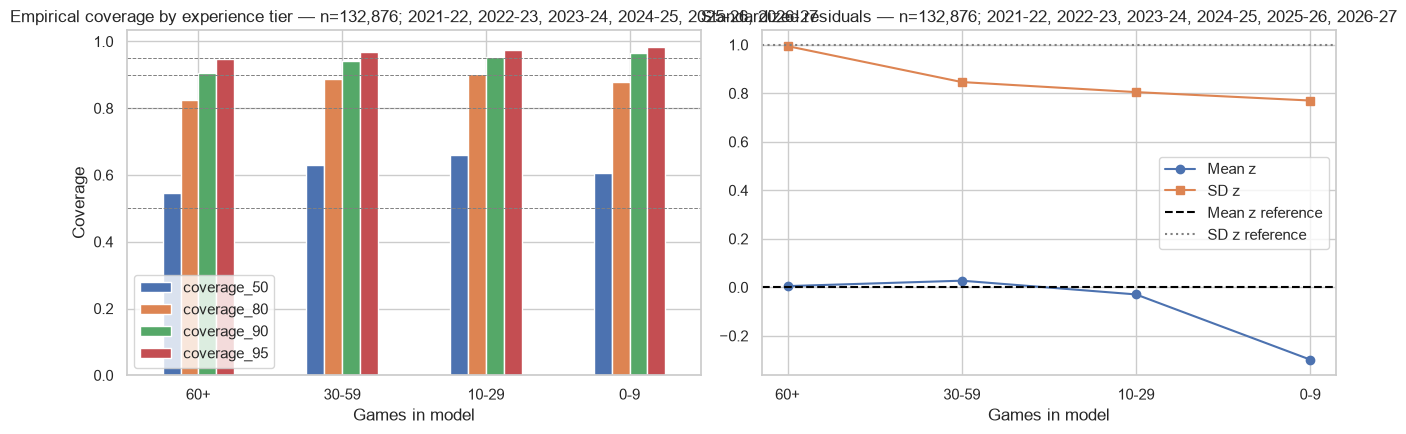

In [3]:
core = core_calibration(trace)
core_table = pd.DataFrame(
    [{key: value for key, value in core.items() if key != "pit_histogram"}]
)
print("Core calibration:")
display(core_table)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(np.arange(10), core["pit_histogram"], width=0.9)
ax.axhline(core["n"] / 10, color="black", linestyle="--", label="Uniform reference")
ax.set(
    title=(
        f"PIT histogram — n={core['n']:,}; "
        f"seasons={', '.join(core['seasons'])}"
    ),
    xlabel="PIT decile (0=lowest)",
    ylabel="Predictions",
)
ax.legend()
plt.show()

variance_report = variance_decomposition(trace)
print("Variance decomposition and coverage by games-in-model tier:")
display(variance_report)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
coverage_columns = ["coverage_50", "coverage_80", "coverage_90", "coverage_95"]
variance_report.set_index("games_tier")[coverage_columns].plot(kind="bar", ax=axes[0])
for level in (0.50, 0.80, 0.90, 0.95):
    axes[0].axhline(level, color="gray", linewidth=0.7, linestyle="--")
axes[0].set(
    title=f"Empirical coverage by experience tier — n={len(trace):,}; {', '.join(evaluation_seasons)}",
    ylabel="Coverage",
    xlabel="Games in model",
)
axes[0].tick_params(axis="x", rotation=0)
axes[1].plot(variance_report["games_tier"].astype(str), variance_report["mean_z"], marker="o", label="Mean z")
axes[1].plot(variance_report["games_tier"].astype(str), variance_report["sd_z"], marker="s", label="SD z")
axes[1].axhline(0, color="black", linestyle="--", label="Mean z reference")
axes[1].axhline(1, color="gray", linestyle=":", label="SD z reference")
axes[1].set(title=f"Standardized residuals — n={len(trace):,}; {', '.join(evaluation_seasons)}", xlabel="Games in model")
axes[1].legend()
plt.tight_layout()
plt.show()


Shrinkage by games-in-model tier:


,games_tier,n,mean_z,mean_innovation
0,60+,108196,0.004861,0.027564
1,30-59,11468,0.027218,0.164428
2,10-29,8097,-0.029450,-0.188930
3,0-9,5115,-0.298218,-1.890569


Shrinkage by pregame-state decile:


,state_decile,n,mean_state,mean_innovation,innovation_se,extreme_decile,toward_zero,significant,under_shrinkage_flag
0,"(-6.398000000000001, -3.175]",13288,-3.824379,0.546010,0.034861,True,True,True,True
1,"(-3.175, -2.382]",13288,-2.762056,0.318644,0.039953,False,True,True,False
2,"(-2.382, -1.706]",13287,-2.044361,0.039893,0.042748,False,True,False,False
3,"(-1.706, -1.01]",13288,-1.362983,-0.134227,0.044752,False,False,True,False
4,"(-1.01, -0.195]",13287,-0.619417,-0.095457,0.048720,False,False,False,False
5,"(-0.195, 0.797]",13288,0.262456,-0.420391,0.052258,False,True,True,False
6,"(0.797, 2.185]",13287,1.460498,-0.064795,0.054886,False,True,False,False
7,"(2.185, 4.293]",13288,3.159303,-0.084128,0.058714,False,True,False,False
8,"(4.293, 7.475]",13287,5.762136,-0.138823,0.064099,False,True,True,False
9,"(7.475, 22.64]",13288,10.912152,-0.443274,0.072355,True,True,True,True


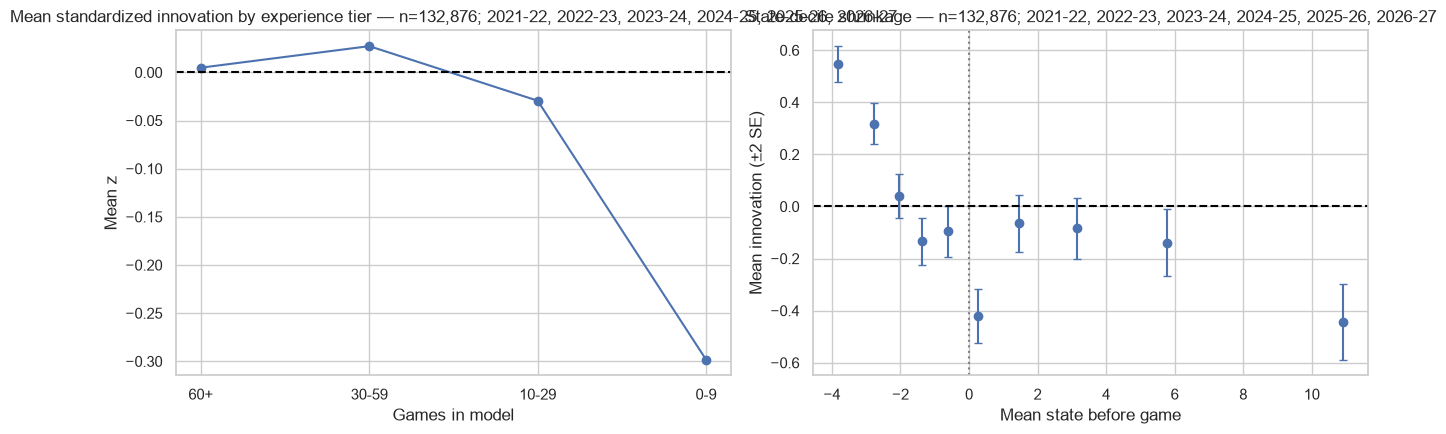

In [4]:
tier_shrinkage, state_decile_shrinkage = shrinkage_summary(trace)
print("Shrinkage by games-in-model tier:")
display(tier_shrinkage)
print("Shrinkage by pregame-state decile:")
display(state_decile_shrinkage)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(tier_shrinkage["games_tier"].astype(str), tier_shrinkage["mean_z"], marker="o")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(
    title=f"Mean standardized innovation by experience tier — n={len(trace):,}; {', '.join(evaluation_seasons)}",
    xlabel="Games in model",
    ylabel="Mean z",
)
axes[1].errorbar(
    state_decile_shrinkage["mean_state"],
    state_decile_shrinkage["mean_innovation"],
    yerr=2 * state_decile_shrinkage["innovation_se"],
    fmt="o",
    capsize=3,
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].axvline(0, color="gray", linestyle=":")
axes[1].set(
    title=f"State-decile shrinkage — n={len(trace):,}; {', '.join(evaluation_seasons)}",
    xlabel="Mean state before game",
    ylabel="Mean innovation (±2 SE)",
)
plt.tight_layout()
plt.show()

Offseason calibration for all requested early windows and their complements:


,window,period,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95
0,5,early,12771,-0.116436,0.903519,0.581395,0.849190,0.925221,0.962180
1,5,rest,103677,0.015789,0.984914,0.553662,0.830126,0.909401,0.947857
2,10,early,23514,-0.065969,0.904504,0.589521,0.854385,0.927192,0.961427
3,10,rest,92934,0.018305,0.994022,0.548400,0.826608,0.907074,0.946392
4,20,early,43651,-0.029940,0.925129,0.584431,0.850221,0.922613,0.957481
5,20,rest,72797,0.020013,1.006658,0.540077,0.821421,0.904254,0.944599


Early-season innovation/state relationship (returners, games 1-20):


,n,slope,intercept,correlation,p_value,slope_se
0,43651,-0.063348,-0.145585,-0.047864,1.440662e-23,0.006328


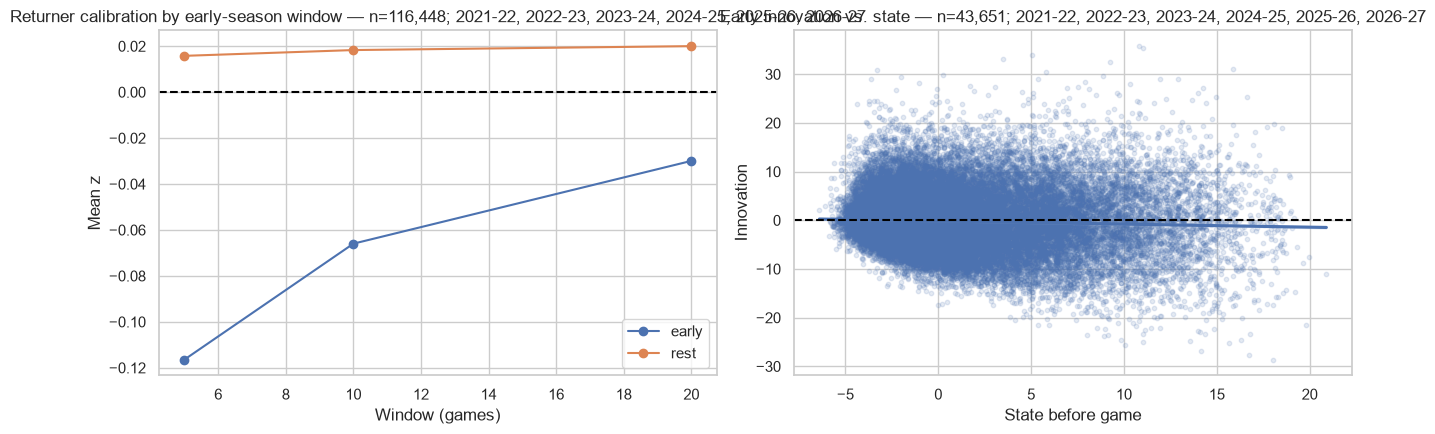

In [5]:
offseason_windows, innovation_state_relationship = offseason_summary(trace)
print("Offseason calibration for all requested early windows and their complements:")
display(offseason_windows)
print("Early-season innovation/state relationship (returners, games 1-20):")
display(pd.DataFrame([innovation_state_relationship]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for period, subset in offseason_windows.groupby("period", sort=False):
    axes[0].plot(subset["window"], subset["mean_z"], marker="o", label=period)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(
    title=f"Returner calibration by early-season window — n={int(trace['returning_player'].sum()):,}; {', '.join(evaluation_seasons)}",
    xlabel="Window (games)",
    ylabel="Mean z",
)
axes[0].legend()
early_returners = trace.loc[trace["returning_player"] & trace["season_game_number"].le(20)]
sns.regplot(data=early_returners, x="state_before", y="innovation", scatter_kws={"alpha": 0.15, "s": 10}, ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(
    title=f"Early innovation vs. state — n={len(early_returners):,}; {', '.join(evaluation_seasons)}",
    xlabel="State before game",
    ylabel="Innovation",
)
plt.tight_layout()
plt.show()

In [6]:
group_reports = {}
for group_column in ("opp_team_id", "team_id", "position"):
    report = group_calibration(trace, group_column, min_n=CONFIG.min_group_n)
    report = report.sort_values(
        ["actionable_flag", "low_sample", "n"],
        ascending=[False, True, False],
        kind="mergesort",
    ).reset_index(drop=True)
    group_reports[group_column] = report
    print(f"Calibration by {group_column} (actionable flags first; low-sample rows retained):")
    display(report)

slice_reports = {}
for flag_column, label in (("new_team_flag", "New-team slice"), ("rookie_flag", "Rookie slice")):
    slice_report = group_calibration(trace, flag_column, min_n=CONFIG.min_group_n)
    slice_report = slice_report.sort_values("actionable_flag", ascending=False, kind="mergesort")
    slice_reports[flag_column] = slice_report
    print(f"{label} (False and True shown separately):")
    display(slice_report)

Calibration by opp_team_id (actionable flags first; low-sample rows retained):


,opp_team_id,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,1610612757,4512,-0.000379,0.964451,0.561613,0.838874,0.915780,0.952128,0.014358,0.010154,False,True,False,True
1,1610612740,4497,-0.015682,0.957939,0.564599,0.838114,0.914832,0.951968,0.014285,0.010102,False,True,False,True
2,1610612764,4493,0.034153,0.991870,0.584242,0.838860,0.911195,0.945248,0.014797,0.010465,True,False,False,True
3,1610612762,4489,0.045673,1.001780,0.549566,0.825574,0.903319,0.942526,0.014952,0.010574,True,False,False,True
4,1610612747,4474,-0.029501,0.938345,0.563478,0.843987,0.921770,0.955297,0.014029,0.009921,True,True,False,True
5,1610612745,4471,-0.014980,0.965735,0.556922,0.830687,0.911653,0.951241,0.014443,0.010214,False,True,False,True
6,1610612766,4462,-0.016540,0.971245,0.555356,0.835948,0.913268,0.949126,0.014540,0.010282,False,True,False,True
7,1610612760,4459,0.023573,0.972218,0.555954,0.834492,0.912312,0.949765,0.014559,0.010296,False,True,False,True
8,1610612765,4456,0.016499,0.977980,0.573833,0.839991,0.912029,0.950853,0.014651,0.010361,False,True,False,True
9,1610612763,4456,0.005508,0.977702,0.546679,0.832361,0.907540,0.947487,0.014647,0.010358,False,True,False,True


Calibration by team_id (actionable flags first; low-sample rows retained):


,team_id,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,1610612760,4630,-0.013927,0.932773,0.569546,0.846436,0.921814,0.958099,0.013708,0.009694,False,True,False,True
1,1610612759,4613,0.006305,0.938165,0.559289,0.845220,0.921309,0.958812,0.013813,0.009768,False,True,False,True
2,1610612749,4545,-0.009850,0.974026,0.576678,0.839824,0.918592,0.950715,0.014448,0.010217,False,True,False,True
3,1610612753,4531,-0.015274,0.919174,0.567866,0.849261,0.928493,0.959832,0.013655,0.009657,False,True,False,True
4,1610612764,4516,0.011391,0.942501,0.562888,0.840124,0.919176,0.955934,0.014025,0.009918,False,True,False,True
5,1610612756,4498,-0.019185,0.958471,0.567141,0.849266,0.919520,0.953535,0.014291,0.010107,False,True,False,True
6,1610612754,4497,-0.007196,0.970429,0.540138,0.832777,0.912608,0.951746,0.014471,0.010234,False,True,False,True
7,1610612750,4497,-0.014208,0.958864,0.588615,0.846342,0.912164,0.952635,0.014299,0.010112,False,True,False,True
8,1610612743,4478,-0.011275,0.969735,0.567441,0.841000,0.916034,0.949531,0.014491,0.010248,False,True,False,True
9,1610612763,4463,0.018291,0.974416,0.549406,0.833520,0.914183,0.954515,0.014586,0.010315,False,True,False,True


Calibration by position (actionable flags first; low-sample rows retained):


,position,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,C,25517,-0.003650,0.887040,0.601050,0.868637,0.936160,0.965317,0.005553,0.003927,False,True,False,True
1,SF,25490,-0.003111,0.951564,0.561867,0.840486,0.916595,0.954374,0.005960,0.004215,False,True,False,True
2,PF,25231,-0.006809,0.937137,0.576117,0.845547,0.921287,0.957037,0.005900,0.004172,False,True,False,True
3,PG,23179,-0.018493,1.038939,0.531429,0.810173,0.895940,0.938522,0.006824,0.004825,True,True,False,True
4,UNK,219,-0.092518,0.772898,0.662100,0.922374,0.972603,0.986301,0.052228,0.037015,False,True,False,True
5,SG,33240,-0.003991,1.003579,0.540915,0.821841,0.905385,0.944344,0.005505,0.003892,False,False,False,False


New-team slice (False and True shown separately):


,new_team_flag,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,False,131606,-0.004773,0.966095,0.561988,0.837089,0.914920,0.951598,0.002663,0.001883,False,True,False,True
1,True,1270,-0.234413,0.908435,0.533071,0.831496,0.915748,0.968504,0.025491,0.018032,True,True,False,True


Rookie slice (False and True shown separately):


,rookie_flag,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,False,116756,0.000822,0.976780,0.556854,0.832403,0.911259,0.949510,0.002859,0.002021,False,True,False,True
1,True,16120,-0.063387,0.880315,0.596898,0.870596,0.941501,0.968052,0.006934,0.004903,True,True,False,True


Kalman gain by broad experience tier:


,games_tier,n,mean_gain,gain_sd,gain_se
0,0-9,5115,0.081415,0.017106,0.000239
1,10-29,8097,0.069998,0.021318,0.000237
2,30-59,11468,0.070388,0.022775,0.000213
3,60+,108196,0.066587,0.018898,0.000057


Kalman gain by fine games-in-model bins:


,games_quantile,n,games_min,games_max,mean_gain,gain_sd,gain_se,season_boundary_n,non_boundary_n,non_boundary_mean_gain,non_boundary_gain_se,gain_jump,gain_jump_se,unexplained_jump_flag
0,0,6835,0,13,0.078997,0.018356,0.000222,135,6700,0.077411,0.000179,NaN,NaN,False
1,1,6767,14,30,0.069458,0.021634,0.000263,169,6598,0.067452,0.000219,-0.009959,0.000283,False
2,2,6446,31,47,0.069850,0.022685,0.000283,184,6262,0.067608,0.000237,0.000157,0.000323,False
3,3,6699,48,64,0.071640,0.023190,0.000283,220,6479,0.069166,0.000238,0.001558,0.000336,True
4,4,6584,65,79,0.073312,0.023298,0.000287,230,6354,0.070784,0.000244,0.001617,0.000341,True
5,5,6788,80,93,0.072017,0.022041,0.000268,201,6587,0.069857,0.000228,-0.000927,0.000334,False
6,6,6893,94,105,0.072333,0.023029,0.000277,245,6648,0.069765,0.000234,-0.000092,0.000327,False
7,7,6835,106,115,0.073181,0.022950,0.000278,240,6595,0.070679,0.000236,0.000914,0.000332,True
8,8,6248,116,123,0.072587,0.022730,0.000288,210,6038,0.070184,0.000245,-0.000496,0.000340,False
9,9,7254,124,131,0.072694,0.022596,0.000265,244,7010,0.070298,0.000226,0.000114,0.000333,False


Kalman gain by season-boundary status:


,season_boundary,n,mean_gain,gain_sd,gain_se
0,False,130185,0.066126,0.016416,0.000045
1,True,2691,0.143531,0.006395,0.000123


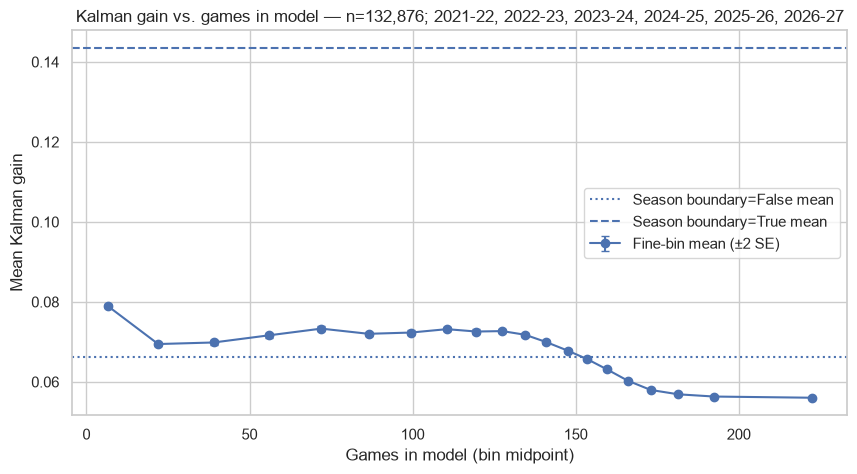

Unexplained positive non-boundary gain jumps:


,games_quantile,n,games_min,games_max,mean_gain,gain_sd,gain_se,season_boundary_n,non_boundary_n,non_boundary_mean_gain,non_boundary_gain_se,gain_jump,gain_jump_se,unexplained_jump_flag
3,3,6699,48,64,0.071640,0.023190,0.000283,220,6479,0.069166,0.000238,0.001558,0.000336,True
4,4,6584,65,79,0.073312,0.023298,0.000287,230,6354,0.070784,0.000244,0.001617,0.000341,True
7,7,6835,106,115,0.073181,0.022950,0.000278,240,6595,0.070679,0.000236,0.000914,0.000332,True


Posterior-draw diagnostics: {'status': 'skipped', 'reason': 'posterior draws unavailable'}


In [7]:
gain_by_tier, gain_by_games, gain_by_boundary = gain_summary(trace)
print("Kalman gain by broad experience tier:")
display(gain_by_tier)
print("Kalman gain by fine games-in-model bins:")
display(gain_by_games)
print("Kalman gain by season-boundary status:")
display(gain_by_boundary)

fig, ax = plt.subplots(figsize=(10, 5))
x = (gain_by_games["games_min"] + gain_by_games["games_max"]) / 2
ax.errorbar(x, gain_by_games["mean_gain"], yerr=2 * gain_by_games["gain_se"], marker="o", capsize=3, label="Fine-bin mean (±2 SE)")
for row in gain_by_boundary.itertuples(index=False):
    ax.axhline(row.mean_gain, linestyle="--" if row.season_boundary else ":", label=f"Season boundary={row.season_boundary} mean")
ax.set(
    title=f"Kalman gain vs. games in model — n={len(trace):,}; {', '.join(evaluation_seasons)}",
    xlabel="Games in model (bin midpoint)",
    ylabel="Mean Kalman gain",
)
ax.legend()
plt.show()

unexplained_jumps = gain_by_games.loc[gain_by_games["unexplained_jump_flag"]]
print("Unexplained positive non-boundary gain jumps:")
if unexplained_jumps.empty:
    print("None")
else:
    display(unexplained_jumps)

draw_report = posterior_draw_summary(trace, draws=None)
print("Posterior-draw diagnostics:", draw_report)

In [8]:
interpretation_lines = ["Diagnostic interpretation and follow-up:"]

for group_column, report in group_reports.items():
    flagged = report.loc[report["actionable_flag"]]
    labels = flagged[group_column].astype(str).tolist()
    preview = ", ".join(labels[:5])
    remainder = len(labels) - min(len(labels), 5)
    preview_text = (
        f"; first flags: {preview}" + (f" (+{remainder} more)" if remainder else "")
        if preview
        else ""
    )
    interpretation_lines.append(
        f"- {group_column}: {len(flagged)} actionable calibration flag(s){preview_text}."
    )

for flag_column, label in (("new_team_flag", "New-team"), ("rookie_flag", "Rookie")):
    report = slice_reports[flag_column]
    flagged_slice = report.loc[report[flag_column] & report["actionable_flag"]]
    true_slice = report.loc[report[flag_column]]
    if true_slice.empty:
        interpretation_lines.append(f"- {label}: no evaluated rows were available.")
    else:
        row = true_slice.iloc[0]
        flag_status = "actionable calibration flag" if not flagged_slice.empty else "no actionable calibration flag"
        interpretation_lines.append(
            f"- {label}: {flag_status}; n={int(row['n']):,}, "
            f"mean z={row['mean_z']:.3f}, SD z={row['sd_z']:.3f}."
        )

slope = float(innovation_state_relationship["slope"])
p_value = float(innovation_state_relationship["p_value"])
if np.isfinite(slope) and np.isfinite(p_value):
    relationship_label = "mean-reversion signal" if slope < 0 else "same-direction signal"
    significance_label = "statistically resolved" if p_value < 0.05 else "not statistically resolved"
    interpretation_lines.append(
        f"- Early-season state/innovation relationship: {relationship_label}; "
        f"slope={slope:.3f}, p={p_value:.3g} ({significance_label})."
    )
else:
    interpretation_lines.append("- Early-season state/innovation relationship: insufficient variation for inference.")

if unexplained_jumps.empty:
    interpretation_lines.append("- Non-boundary gain jumps: none exceeded the diagnostic threshold.")
else:
    jump_bins = ", ".join(
        f"{int(row.games_min)}-{int(row.games_max)} games"
        for row in unexplained_jumps.itertuples(index=False)
    )
    interpretation_lines.append(
        f"- Non-boundary gain jumps: {len(unexplained_jumps)} flagged bin(s) ({jump_bins}); investigate before operational use."
    )

interpretation_lines.append(
    "These diagnostics identify follow-up checks only; they do not constitute deployment approval."
)
print("\n".join(interpretation_lines))

Diagnostic interpretation and follow-up:
- opp_team_id: 28 actionable calibration flag(s); first flags: 1610612757, 1610612740, 1610612764, 1610612762, 1610612747 (+23 more).
- team_id: 20 actionable calibration flag(s); first flags: 1610612760, 1610612759, 1610612749, 1610612753, 1610612764 (+15 more).
- position: 5 actionable calibration flag(s); first flags: C, SF, PF, PG, UNK.
- New-team: actionable calibration flag; n=1,270, mean z=-0.234, SD z=0.908.
- Rookie: actionable calibration flag; n=16,120, mean z=-0.063, SD z=0.880.
- Early-season state/innovation relationship: mean-reversion signal; slope=-0.063, p=1.44e-23 (statistically resolved).
- Non-boundary gain jumps: 3 flagged bin(s) (48-64 games, 65-79 games, 106-115 games); investigate before operational use.
These diagnostics identify follow-up checks only; they do not constitute deployment approval.


## Latest-season live-state monitoring

This section uses the latest two complete prior seasons as the training window and processes the latest available season sequentially with the same causal API. The table is a snapshot of each player's state after their most recently observed game. It is **monitoring, not a future-game forecast**: there is no future schedule, opponent, or role row from which to construct a pregame prediction.

In [9]:
latest_season = available_seasons[-1]
prior_seasons = available_seasons[:-1]
if len(prior_seasons) < CONFIG.train_window_seasons:
    raise ValueError("latest-season monitoring needs two complete prior seasons")
live_training_seasons = tuple(prior_seasons[-CONFIG.train_window_seasons :])
live_seasons = (*live_training_seasons, latest_season)
live_frame = causal.loc[causal["season_year"].astype(str).isin(live_seasons)].copy()
live_trace, live_fold_audits = walk_forward_trace(
    live_frame,
    evaluation_seasons=(latest_season,),
    config=CONFIG,
)
print(
    f"Live-state window: train on {', '.join(live_training_seasons)}; "
    f"causally monitor {latest_season}."
)
print("Latest-season fold audit:")
display(pd.DataFrame(live_fold_audits))

if live_trace.empty:
    raise AssertionError("latest-season live-state trace must not be empty")
latest_rows = (
    live_trace.sort_values(["player_id", "game_date", "game_id"], kind="mergesort")
    .groupby("player_id", sort=False, as_index=False)
    .tail(1)
    .copy()
)
latest_rows["state_sd_after"] = np.sqrt(latest_rows["state_var_after"])
latest_rows["games_in_model"] = latest_rows["games_in_model_before"] + 1
monitoring_columns = [
    "player_name",
    "player_id",
    "team_id",
    "game_date",
    "state_after",
    "state_sd_after",
    "games_in_model",
    "predictive_mean",
    "points",
    "innovation",
    "z",
    "pit",
    "kalman_gain",
]
latest_state_monitoring = latest_rows.loc[:, monitoring_columns].sort_values(
    ["state_after", "player_name"], ascending=[False, True], kind="mergesort"
)
if not np.isfinite(latest_state_monitoring.select_dtypes(include="number").to_numpy(dtype=float)).all():
    raise AssertionError("latest-season monitoring diagnostics must be finite")
print(
    f"Latest-season state monitoring (n={len(latest_state_monitoring):,} players). "
    "Observed-state snapshot; not a future-game forecast."
)
display(latest_state_monitoring.reset_index(drop=True))

Live-state window: train on 2024-25, 2025-26; causally monitor 2026-27.
Latest-season fold audit:


,train_seasons,evaluation_season,candidate_rows,fitted_rows,zero_minute_rows_removed,imputed_feature_cells,predicted_rows,evaluation_imputed_feature_cells,evaluation_rows_with_imputation
0,"(2024-25, 2025-26)",2026-27,52952,52952,0,1778,1597,580,430


Latest-season state monitoring (n=430 players). Observed-state snapshot; not a future-game forecast.


,player_name,player_id,team_id,game_date,state_after,state_sd_after,games_in_model,predictive_mean,points,innovation,z,pit,kalman_gain
0,Luka Dončić,1629029,1610612747,2026-10-27,18.593063,1.978583,118,36.430512,41.0,4.569488,0.708110,0.760560,0.105045
1,Anthony Edwards,1630162,1610612750,2026-10-26,16.917540,1.978632,144,26.283241,47.0,20.716759,3.210361,0.999337,0.105050
2,Victor Wembanyama,1641705,1610612759,2026-10-28,13.316884,1.908579,115,24.622973,36.0,11.377027,1.770217,0.961652,0.097743
3,Giannis Antetokounmpo,203507,1610612748,2026-10-28,13.022872,1.910976,108,29.142081,24.0,-5.142081,-0.799977,0.211864,0.097989
4,Shai Gilgeous-Alexander,1628983,1610612760,2026-10-28,12.921092,1.908542,149,27.643100,21.0,-6.643100,-1.033640,0.150655,0.097739
...,...,...,...,...,...,...,...,...,...,...,...,...,...
425,Micah Peavy,1642877,1610612760,2026-10-28,-4.532517,2.285877,62,10.907828,0.0,-10.907828,-1.656791,0.048784,0.140207
426,Tyus Jones,1626145,1610612743,2026-10-28,-4.637065,1.978548,152,1.470204,5.0,3.529796,0.546996,0.707808,0.105041
427,Drake Powell,1642962,1610612751,2026-10-25,-4.642985,2.285843,64,8.236551,0.0,-8.236551,-1.251053,0.105460,0.140203
428,Kris Murray,1631200,1610612763,2026-10-29,-4.878293,2.162810,128,2.573486,0.0,-2.573486,-0.394212,0.346713,0.125517


## Shot model: editable minutes and rate covariates

This cell is the place to turn slopes on and off. `SPEC` lists the minutes-mean columns and the attempt-log-rate columns. Delete a name to drop that slope. A name can appear in both tuples; each equation gets its own coefficient.

Minutes noise (`min_sd`) and the minutes-walk step (`min_sd_drift`) are learned per player. Each is a log-scale pool: a population mean, a population spread, and a unit deviation `min_sd_z` or `min_sd_drift_z`. A typical player is about six minutes of noise and about a one-minute step per 14-day block.

The context columns use only earlier games, except `stars_out`, which is how many of this team's stars have no positive-minute row in the current game. A star is one of the top `star_slots` teammates by prior minutes, and only if that mean is at least `star_min_minutes`. `usg_stars_in` and `usg_stars_out` are that player's prior usage when those stars played and when at least one sat. A regime with no prior games is filled from the player's own prior usage, and the audit counts those fills. `points_trend` is the prior 3-game points mean minus the prior 10-game mean. `opp_def_prior` and `opp_pace_prior` are the opponent's prior team defense and pace.

`HISTORY` is 2024-25, 2025-26, and 2026-27. `MAX_DAYS` clips only 2026-27; `None` keeps that season whole. Trailing priors use a 4-game half-life, so a newer game counts more than an older one inside the same window. Opening-night rest stays 7 days. Leave `PRIOR_DRAWS` at 0 until you want a prior check.

In [10]:
import pymc as pm

from src.models.hierarchical_points import (
    MINUTES_UPPER,
    CovariateSpec,
    build_design,
    build_model,
    crps_ensemble,
    default_slope_config,
    PRIOR_HALF_LIFE_GAMES,
    expanded_covariates,
)

# Delete a name to drop that slope. Reorder to change the coefficient index.
SPEC = expanded_covariates()
# Turn one slope on at a time. False keeps the original shared coefficient.
SLOPES = default_slope_config()
# SPEC = CovariateSpec(
#     minutes=("spread", "total", "rest_days", "b2b", "minutes_trail", "starter"),
#     rate=("is_home", "pace_prior", "rest_days"),
#     star_slots=2,
#     star_min_minutes=24.0,
#     trend_short=3,
#     trend_long=10,
# )
HISTORY = ("2024-25", "2025-26", "2026-27")
MAX_DAYS = 28  # clips 2026-27 only; None keeps that season whole
PRIOR_DRAWS = 0

HIER_COLUMNS = [
    "season_type",
    "season_year",
    "game_date",
    "game_id",
    "player_id",
    "team_id",
    "opp_team_id",
    "pos",
    "matchup",
    "minutes",
    "fga",
    "fgm",
    "fg3_a",
    "fg3_m",
    "fta",
    "ftm",
    "pts",
    "start_position",
    "game_total",
    "player_team_spread",
    "team_pace",
    "team_def_rating",
    "usg_pct",
]
pieces = []
for season in HISTORY:
    season_path = next(path for path in SEASON_PATHS if season in path.parts)
    season_games = pd.read_parquet(season_path, columns=HIER_COLUMNS)
    season_games = season_games.loc[season_games["season_type"].eq("Regular Season")].copy()
    if MAX_DAYS is not None and season == "2026-27":
        dates = pd.to_datetime(season_games["game_date"])
        season_games = season_games.loc[dates.le(dates.min() + pd.Timedelta(days=MAX_DAYS))].copy()
    pieces.append(season_games)
shot_games = pd.concat(pieces, ignore_index=True)
shot_design = build_design(shot_games, covariates=SPEC)
print(
    f"{', '.join(HISTORY)} models "
    f"{shot_design.audit['output_rows']:,} rows, "
    f"{shot_design.n_players} players, {shot_design.n_blocks} blocks. "
    f"Prior half-life {PRIOR_HALF_LIFE_GAMES:g} games."
)
print("Minutes slopes:", ", ".join(shot_design.minutes_columns))
print("Attempt slopes:", ", ".join(shot_design.rate_columns))
print("Player-level slopes:", {name: SLOPES.enabled(name) for name in SLOPES.varying})
print(
    "Player scales: min_sd (noise) and min_sd_drift (walk step), "
    "each with _log_mu, _log_sd, and _z."
)
display(pd.Series(shot_design.audit, name="rows").to_frame())

if PRIOR_DRAWS:
    shot_model = build_model(
        shot_design.data,
        shot_design.n_players,
        shot_design.n_teams,
        shot_design.n_pos,
        shot_design.n_blocks,
        minutes_columns=shot_design.minutes_columns,
        rate_columns=shot_design.rate_columns,
        slopes=SLOPES,
    )
    with shot_model:
        shot_prior = pm.sample_prior_predictive(draws=PRIOR_DRAWS, random_seed=0)

    def _prior_matrix(name: str) -> np.ndarray:
        values = np.asarray(shot_prior.prior_predictive[name].values)
        return values.reshape(-1, shot_design.audit["output_rows"])

    prior_minutes = _prior_matrix("minutes")
    prior_points = (
        2 * _prior_matrix("fgm2") + 3 * _prior_matrix("fgm3") + _prior_matrix("ftm")
    )
    chain_ok = (
        np.all((prior_minutes > 0) & (prior_minutes <= MINUTES_UPPER))
        and np.all(_prior_matrix("fgm2") <= _prior_matrix("fga2"))
        and np.all(_prior_matrix("fgm3") <= _prior_matrix("fga3"))
        and np.all(_prior_matrix("ftm") <= _prior_matrix("fta"))
    )
    print(f"Prior chain respects minutes bounds and makes ≤ attempts: {chain_ok}")
    print(
        f"Prior mean minutes {prior_minutes.mean():.1f}; "
        f"observed mean minutes {shot_design.data['minutes'].mean():.1f}."
    )
    print(
        "Prior CRPS on the first modeled row: "
        f"{crps_ensemble(prior_points[:, 0], shot_design.points[0]):.2f}. "
        "The posterior has not been fit; this is a prior check."
    )


2025-26 from 2025-10-21 models 3,896 rows, 453 players, 2 blocks.
Minutes slopes: spread, total, rest_days, b2b, minutes_trail, starter, opp_def_prior, opp_pace_prior, stars_out, points_trend
Attempt slopes: is_home, pace_prior, rest_days, opp_def_prior, opp_pace_prior, stars_out, usg_stars_in, usg_stars_out, points_trend
Player scales: min_sd (noise) and min_sd_drift (walk step), each with _log_mu, _log_sd, and _z.


,rows
input_rows,4737
nonpositive_minute_rows_removed,0
missing_shot_rows_removed,0
season_opener_rest_filled,470
usg_stars_in_filled,56
usg_stars_out_filled,2951
missing_position_filled,15
players_with_mixed_positions,0
missing_market_rows_removed,364
no_prior_minutes_rows_removed,458
